In [3]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)


In [4]:

import pandas as pd

url = "https://raw.githubusercontent.com/MakroMB/student-performance-analysis/main/data/student-mat.csv"

df = pd.read_csv(url, sep=';')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [5]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all'))

print("\nFirst 5 Records:")
display(df.head())


Dataset Shape: (395, 33)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395,395,395.000000,395,395,395,395.000000,395.000000,395,395,...,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,349,208,NaN,307,281,354,NaN,NaN,141,217,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,16.696203,NaN,NaN,NaN,2.749367,2.521519,NaN,NaN,...,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,NaN,NaN,1.276043,NaN,NaN,NaN,1.094735,1.088201,NaN,NaN,...,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,...,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,NaN,NaN,17.000000,NaN,NaN,NaN,3.000000,2.000000,NaN,NaN,...,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000



First 5 Records:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Records:", df.duplicated().sum())


Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total Missing Values: 0

Duplicate Records: 0


In [7]:

df = df.drop_duplicates().copy()

print("Dataset Shape After Duplicate Check:", df.shape)


Dataset Shape After Duplicate Check: (395, 33)


In [8]:

df['Result'] = (df['G3'] >= 10).astype(int)

print("Pass and Fail Counts:")
print(df['Result'].value_counts())

print("\nResult Meaning:")
print("0 = Fail")
print("1 = Pass")

display(df[['G3', 'Result']].head(10))


Pass and Fail Counts:
Result
1    265
0    130
Name: count, dtype: int64

Result Meaning:
0 = Fail
1 = Pass


,G3,Result
0,6,0
1,6,0
2,10,1
3,15,1
4,10,1
5,15,1
6,11,1
7,6,0
8,19,1
9,15,1


In [9]:

# Separate input features and target

X = df.drop(columns=['G1', 'G2', 'G3', 'Result'])
y = df['Result']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())


Input Features Shape: (395, 30)
Target Shape: (395,)

Input Features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Target Distribution:
Result
1    265
0    130
Name: count, dtype: int64


In [10]:

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical Features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining and testing split completed!")


Training Data: (316, 30)
Testing Data: (79, 30)

Training and testing split completed!


In [12]:

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Data preprocessing setup completed!")


Data preprocessing setup completed!


In [13]:

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    trained_models[name] = pipeline

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print(name, "trained successfully!")

print("\nAll models trained successfully!")


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!

All models trained successfully!


In [14]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

print("Machine Learning Model Comparison:")
display(results_df.round(4))

best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

print("\nBest Model Based on F1 Score:", best_model_name)


Machine Learning Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.6582,0.7167,0.8113,0.7611
1,Random Forest,0.6329,0.6765,0.8679,0.7603
2,Decision Tree,0.6076,0.7292,0.6604,0.6931



Best Model Based on F1 Score: Logistic Regression


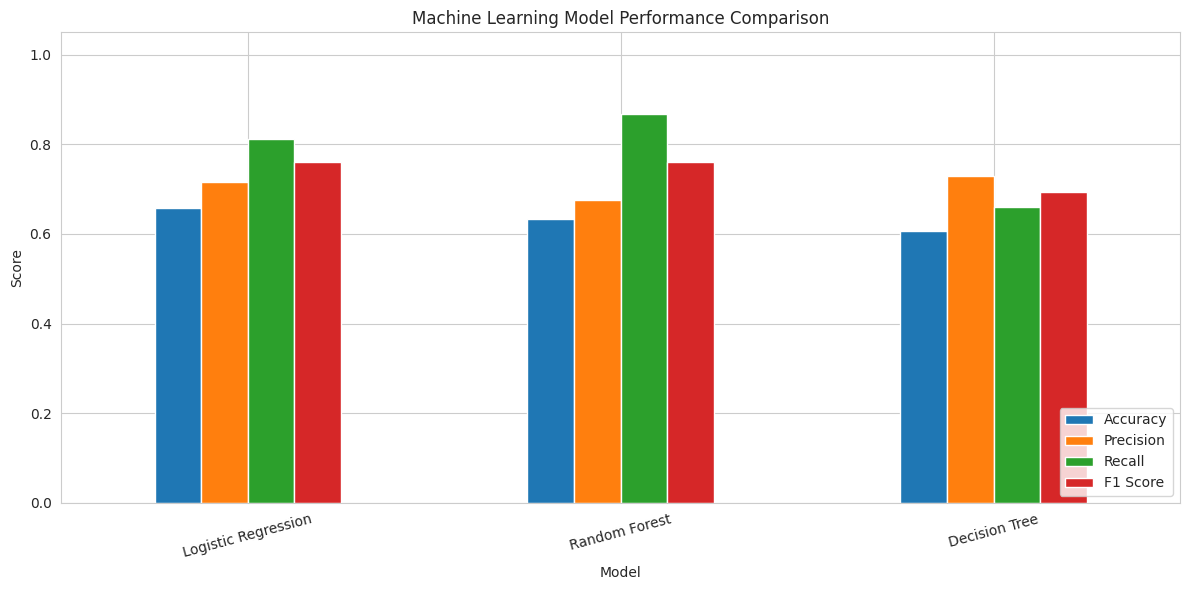

In [15]:

results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig('model_performance_comparison.png', dpi=300)
plt.show()


In [16]:

for name, pipeline in trained_models.items():

    print("\nModel:", name)

    y_pred = pipeline.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['Fail', 'Pass'],
        zero_division=0
    ))



Model: Logistic Regression
              precision    recall  f1-score   support

        Fail       0.47      0.35      0.40        26
        Pass       0.72      0.81      0.76        53

    accuracy                           0.66        79
   macro avg       0.60      0.58      0.58        79
weighted avg       0.64      0.66      0.64        79


Model: Decision Tree
              precision    recall  f1-score   support

        Fail       0.42      0.50      0.46        26
        Pass       0.73      0.66      0.69        53

    accuracy                           0.61        79
   macro avg       0.57      0.58      0.57        79
weighted avg       0.63      0.61      0.62        79


Model: Random Forest
              precision    recall  f1-score   support

        Fail       0.36      0.15      0.22        26
        Pass       0.68      0.87      0.76        53

    accuracy                           0.63        79
   macro avg       0.52      0.51      0.49        79
we

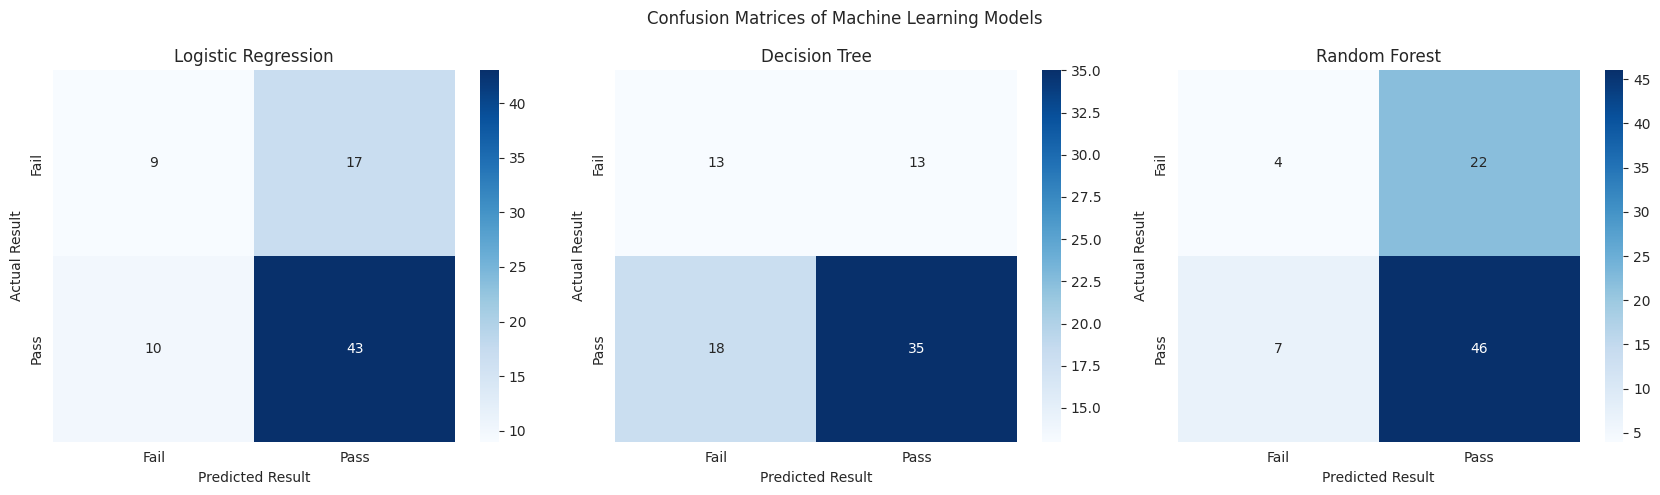

In [17]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, pipeline) in zip(axes, trained_models.items()):

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Fail', 'Pass'],
        yticklabels=['Fail', 'Pass'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Result")
    ax.set_ylabel("Actual Result")

plt.suptitle("Confusion Matrices of Machine Learning Models")
plt.tight_layout()

plt.savefig('confusion_matrix.png', dpi=300)
plt.show()


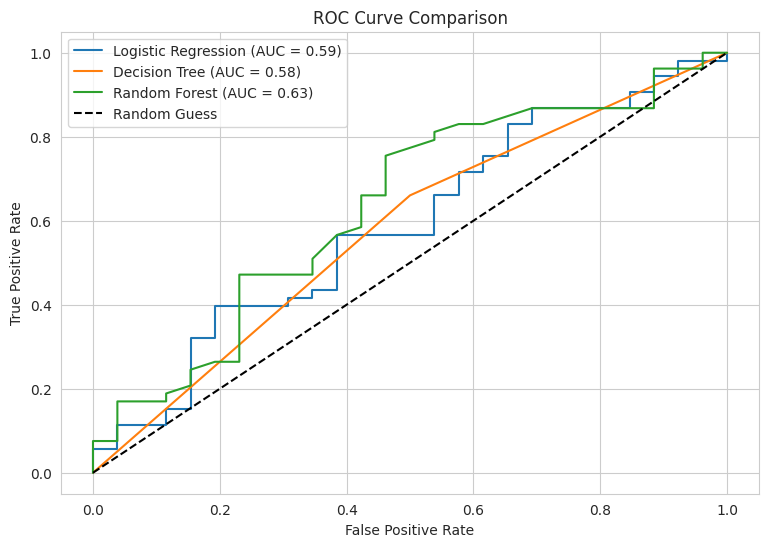

In [18]:

plt.figure(figsize=(9, 6))

for name, pipeline in trained_models.items():

    y_probability = pipeline.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_probability
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc:.2f})'
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.savefig('roc_curve.png', dpi=300)
plt.show()


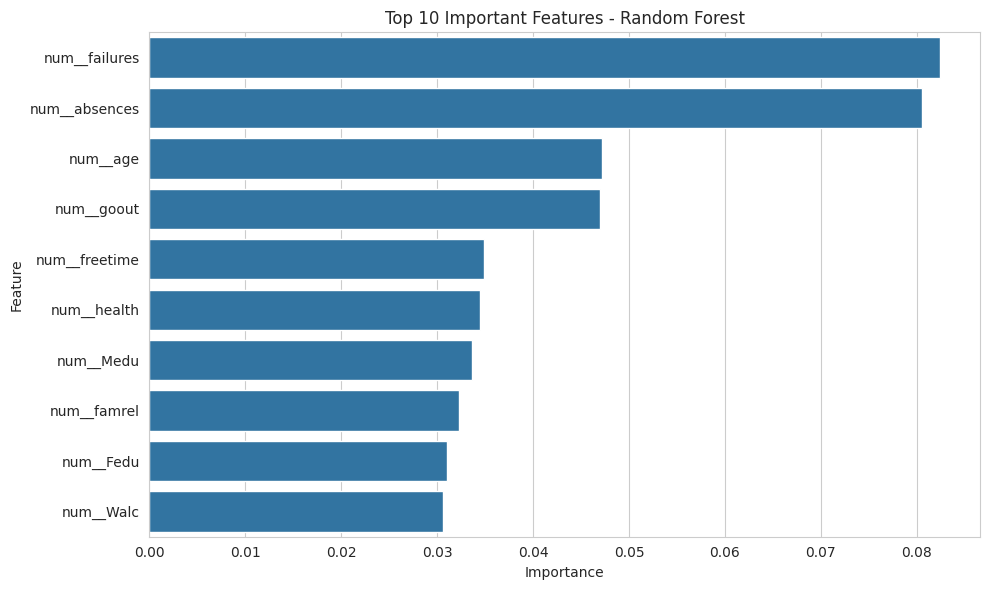

In [19]:

rf_model = trained_models['Random Forest']

feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = rf_model.named_steps[
    'classifier'
].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()

plt.savefig('feature_importance.png', dpi=300)
plt.show()


In [20]:

sample_student = X_test.iloc[[0]]

prediction = best_model.predict(sample_student)[0]

probability = best_model.predict_proba(sample_student)[0]

print("Predicted Result:",
      "PASS" if prediction == 1 else "FAIL")

print("Probability of Fail:", round(probability[0] * 100, 2), "%")
print("Probability of Pass:", round(probability[1] * 100, 2), "%")


Predicted Result: FAIL
Probability of Fail: 69.86 %
Probability of Pass: 30.14 %


In [21]:

# Save processed dataset
df.to_csv('student_performance_dataset.csv', index=False)

# Save model comparison results
results_df.to_csv('model_performance_results.csv', index=False)

print("Project files saved successfully!")


Project files saved successfully!


In [22]:
from google.colab import files
files.download('student_performance_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
files.download('model_performance_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
files.download('confusion_matrix.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
files.download('roc_curve.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
files.download('feature_importance.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>